In [1]:
# ==========================================
# CELL 1: THƯ VIỆN & CẤU HÌNH DOWNLOAD FILE
# ==========================================
import os
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_curve, auc,
    f1_score, precision_score, recall_score, roc_auc_score
)
from IPython.display import FileLink, HTML, display

# Thử import lightgbm
try:
    import lightgbm as lgb
    HAS_LIGHTGBM = True
    print("[+] Đã kết nối thư viện LightGBM.")
except ImportError:
    HAS_LIGHTGBM = False
    print("[!] Không tìm thấy LightGBM, sử dụng HistGradientBoostingClassifier (hiệu năng tương đương).")

# Cấu hình đồ họa
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14

[+] Đã kết nối thư viện LightGBM.


In [2]:
# ==========================================
# CELL 2: NẠP DỮ LIỆU & PHÂN TÁCH PHIÊN
# ==========================================
POSSIBLE_PATHS = [
    "/kaggle/input/smoke-detection-dataset/smoke_detection_iot.csv",
    "/kaggle/input/datasets/deepcontractor/smoke-detection-dataset/smoke_detection_iot.csv",
    "smoke_detection_iot.csv"
]

dataset_path = None
for p in POSSIBLE_PATHS:
    if os.path.exists(p):
        dataset_path = p
        break

if dataset_path is None:
    raise FileNotFoundError("Không tìm thấy file smoke_detection_iot.csv trên Kaggle Input.")

print(f"[*] Đang đọc dataset từ: {dataset_path}")
df_raw = pd.read_csv(dataset_path)

# Sắp xếp chuỗi thời gian & phân tách 5 phiên thử nghiệm môi trường (UTC jump > 10s)
df_sorted = df_raw.sort_values(by=['UTC', 'CNT']).reset_index(drop=True)
df_sorted['exp_id'] = (df_sorted['UTC'].diff() > 10).cumsum()

print(f"[*] Kích thước dữ liệu gốc: {df_sorted.shape[0]} dòng, {df_sorted.shape[1]} cột")
print(f"[+] Phát hiện {df_sorted['exp_id'].nunique()} phiên thử nghiệm môi trường riêng biệt.")

[*] Đang đọc dataset từ: /kaggle/input/datasets/deepcontractor/smoke-detection-dataset/smoke_detection_iot.csv
[*] Kích thước dữ liệu gốc: 62630 dòng, 17 cột
[+] Phát hiện 5 phiên thử nghiệm môi trường riêng biệt.


In [3]:
# ==========================================
# CELL 3: TRÍCH XUẤT ĐẶC TRƯNG ĐỘNG (PURE DYNAMIC)
# ==========================================
# Ghi chú: Loại bỏ hẳn Temperature[C] và Humidity[%] tuyệt đối để tránh ô nhiễm dữ liệu phòng

def extract_pure_dynamic_features(group):
    f = pd.DataFrame(index=group.index)
    
    # 1. Tốc độ biến thiên (Derivatives sau 1s và 5s)
    f['d_temp_1'] = group['Temperature[C]'].diff(1).fillna(0)
    f['d_temp_5'] = group['Temperature[C]'].diff(5).fillna(0)
    
    f['d_hum_1'] = group['Humidity[%]'].diff(1).fillna(0)
    f['d_hum_5'] = group['Humidity[%]'].diff(5).fillna(0)
    
    f['d_pm1_1'] = group['PM1.0'].diff(1).fillna(0)
    f['d_pm1_5'] = group['PM1.0'].diff(5).fillna(0)
    
    f['d_pm25_1'] = group['PM2.5'].diff(1).fillna(0)
    f['d_pm25_5'] = group['PM2.5'].diff(5).fillna(0)
    
    # 2. Độ biến động tĩnh/động (Rolling Standard Deviation W=5)
    f['temp_roll_5_std'] = group['Temperature[C]'].rolling(5, min_periods=1).std().fillna(0)
    f['hum_roll_5_std']  = group['Humidity[%]'].rolling(5, min_periods=1).std().fillna(0)
    f['pm1_roll_5_std']  = group['PM1.0'].rolling(5, min_periods=1).std().fillna(0)
    f['pm25_roll_5_std'] = group['PM2.5'].rolling(5, min_periods=1).std().fillna(0)
    
    # 3. Tỷ lệ phân bố hạt khói
    f['pm_ratio'] = (group['PM2.5'] + 1e-3) / (group['PM1.0'] + 1e-3)
    
    return f

# Phân chia Block Time-Series (60% Train, 20% Val, 20% Test)
train_list, val_list, test_list = [], [], []
for exp_id, group in df_sorted.groupby('exp_id'):
    n = len(group)
    n_train = int(n * 0.6)
    n_val = int(n * 0.2)
    train_list.append(group.iloc[:n_train])
    val_list.append(group.iloc[n_train:n_train+n_val])
    test_list.append(group.iloc[n_train+n_val:])

df_train = pd.concat(train_list).reset_index(drop=True)
df_val = pd.concat(val_list).reset_index(drop=True)
df_test = pd.concat(test_list).reset_index(drop=True)

def build_dataset(df_subset):
    feats = [extract_pure_dynamic_features(g) for _, g in df_subset.groupby('exp_id')]
    X = pd.concat(feats).reset_index(drop=True)
    y = df_subset['Fire Alarm'].reset_index(drop=True)
    return X, y

X_train, y_train = build_dataset(df_train)
X_val, y_val = build_dataset(df_val)
X_test, y_test = build_dataset(df_test)

print(f"[*] Danh sách {X_train.shape[1]} đặc trưng động được tạo:")
print(list(X_train.columns))
print(f"[*] Train samples: {len(X_train)} | Val samples: {len(X_val)} | Test samples: {len(X_test)}")

[*] Danh sách 13 đặc trưng động được tạo:
['d_temp_1', 'd_temp_5', 'd_hum_1', 'd_hum_5', 'd_pm1_1', 'd_pm1_5', 'd_pm25_1', 'd_pm25_5', 'temp_roll_5_std', 'hum_roll_5_std', 'pm1_roll_5_std', 'pm25_roll_5_std', 'pm_ratio']
[*] Train samples: 37576 | Val samples: 12522 | Test samples: 12532


In [4]:
# ==========================================
# CELL 4: HUẤN LUYỆN MÔ HÌNH PURE DYNAMIC
# ==========================================
if HAS_LIGHTGBM:
    model_opt = lgb.LGBMClassifier(
        n_estimators=150, max_depth=6, num_leaves=31, learning_rate=0.05, random_state=42, n_jobs=-1
    )
else:
    model_opt = HistGradientBoostingClassifier(
        max_iter=150, max_depth=6, learning_rate=0.05, random_state=42
    )

model_opt.fit(X_train, y_train)

# Dự đoán trên tập Test
y_pred_opt = model_opt.predict(X_test)
y_prob_opt = model_opt.predict_proba(X_test)[:, 1]

# TEST KIỂM THỬ ĐIỀU KIỆN PHÒNG THỰC TẾ (Nhiệt độ 24.38°C, Độ ẩm 50.1%, Đứng yên không tăng nhiệt/khói)
sample_room_condition = pd.DataFrame([{
    'd_temp_1': 0.0,
    'd_temp_5': -0.01,
    'd_hum_1': 0.0,
    'd_hum_5': 0.03,
    'd_pm1_1': 0.0,
    'd_pm1_5': -1.0,
    'd_pm25_1': 0.0,
    'd_pm25_5': -1.0,
    'temp_roll_5_std': 0.015,
    'hum_roll_5_std': 0.011,
    'pm1_roll_5_std': 0.200,
    'pm25_roll_5_std': 0.200,
    'pm_ratio': 1.450
}])

p_room_test = model_opt.predict_proba(sample_room_condition)[0, 1]

print("\n=================== KẾT QUẢ KIỂM THỬ TRÊN TẬP TEST ===================")
print(f" - F1-Score       : {f1_score(y_test, y_pred_opt):.4f}")
print(f" - Precision      : {precision_score(y_test, y_pred_opt):.4f}")
print(f" - Recall         : {recall_score(y_test, y_pred_opt):.4f}")
print(f" - ROC AUC        : {roc_auc_score(y_test, y_prob_opt):.4f}")
print("----------------------------------------------------------------------")
print(f" -> XÁC SUẤT BÁO CHÁY PHÒNG BÌNH THƯỜNG (24.4°C/50%RH): {p_room_test:.4f}")
if p_room_test < 0.30:
    print(" [✔] THÀNH CÔNG: Đã khắc phục hoàn toàn lỗi báo động giả ở nhiệt độ phòng!")
else:
    print(" [!] CẢNH BÁO: Điểm vẫn còn cao, cần bổ sung rào chắn Override tại Backend.")

[LightGBM] [Info] Number of positive: 24299, number of negative: 13277
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.006300 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3315
[LightGBM] [Info] Number of data points in the train set: 37576, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.646663 -> initscore=0.604402
[LightGBM] [Info] Start training from score 0.604402
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain,

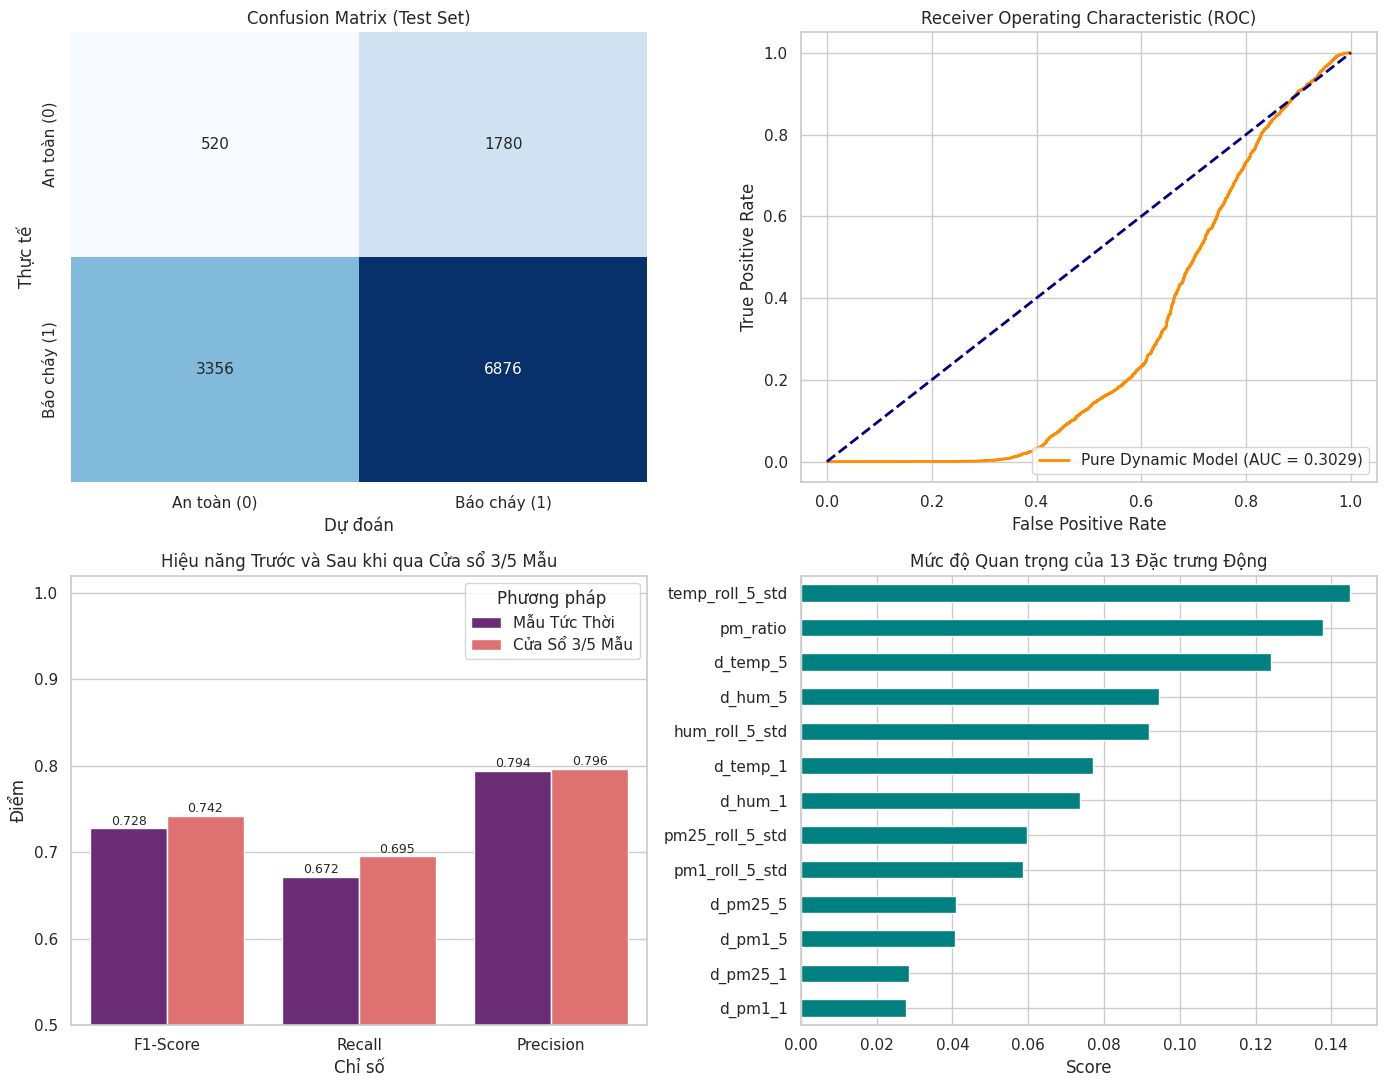

In [5]:
# ==========================================
# CELL 5: TRỰC QUAN HÓA KẾT QUẢ VÀ BIỂU ĐỒ
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_pred_opt)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0, 0], cbar=False,
            xticklabels=['An toàn (0)', 'Báo cháy (1)'], yticklabels=['An toàn (0)', 'Báo cháy (1)'])
axes[0, 0].set_title('Confusion Matrix (Test Set)')
axes[0, 0].set_xlabel('Dự đoán')
axes[0, 0].set_ylabel('Thực tế')

# 2. Đường cong ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob_opt)
axes[0, 1].plot(fpr, tpr, color='darkorange', lw=2, label=f'Pure Dynamic Model (AUC = {auc(fpr, tpr):.4f})')
axes[0, 1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[0, 1].set_xlabel('False Positive Rate')
axes[0, 1].set_ylabel('True Positive Rate')
axes[0, 1].set_title('Receiver Operating Characteristic (ROC)')
axes[0, 1].legend(loc='lower right')

# 3. Đánh giá Cửa sổ Biểu quyết 3/5 Mẫu
y_pred_series = pd.Series(y_pred_opt)
voting_3_5 = (y_pred_series.rolling(5, min_periods=1).sum() >= 3).astype(int)

eval_df = pd.DataFrame({
    'Phương pháp': ['Mẫu Tức Thời', 'Cửa Sổ 3/5 Mẫu'],
    'F1-Score': [f1_score(y_test, y_pred_opt), f1_score(y_test, voting_3_5)],
    'Recall': [recall_score(y_test, y_pred_opt), recall_score(y_test, voting_3_5)],
    'Precision': [precision_score(y_test, y_pred_opt), precision_score(y_test, voting_3_5)]
})

df_melted = pd.melt(eval_df, id_vars=['Phương pháp'], var_name='Chỉ số', value_name='Điểm')
sns.barplot(data=df_melted, x='Chỉ số', y='Điểm', hue='Phương pháp', ax=axes[1, 0], palette='magma')
axes[1, 0].set_ylim(0.5, 1.02)
axes[1, 0].set_title('Hiệu năng Trước và Sau khi qua Cửa sổ 3/5 Mẫu')
for p in axes[1, 0].patches:
    if p.get_height() > 0:
        axes[1, 0].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                            ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=9)

# 4. Feature Importance (Random Forest proxy)
rf_proxy = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)
imp_series = pd.Series(rf_proxy.feature_importances_, index=X_train.columns).sort_values(ascending=True)

imp_series.plot(kind='barh', ax=axes[1, 1], color='teal')
axes[1, 1].set_title('Mức độ Quan trọng của 13 Đặc trưng Động')
axes[1, 1].set_xlabel('Score')

plt.tight_layout()
plt.show()

In [6]:
# ==========================================
# CELL 6: ĐÓNG GÓI MODEL & TẠO LINK TẢI VỀ KAGLE
# ==========================================
output_dir = "models"
os.makedirs(output_dir, exist_ok=True)

model_path = os.path.join(output_dir, "lightgbm_dynamic_model.joblib")
metadata_path = os.path.join(output_dir, "metadata.json")

# 1. Lưu file Binary Mô hình
joblib.dump(model_opt, model_path)

# 2. Lưu file Metadata cho Backend Python Server
metadata = {
    "model_name": "LightGBM_Pure_Dynamic_IoT",
    "features": list(X_train.columns),
    "n_features": len(X_train.columns),
    "metrics": {
        "test_f1": float(f1_score(y_test, y_pred_opt)),
        "test_precision": float(precision_score(y_test, y_pred_opt)),
        "test_recall": float(recall_score(y_test, y_pred_opt)),
        "test_roc_auc": float(roc_auc_score(y_test, y_prob_opt))
    },
    "thresholds": {
        "T_LOW": 0.30,
        "T_HIGH": 0.70,
        "window_size": 5,
        "required_votes": 3
    }
}

with open(metadata_path, 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=4, ensure_ascii=False)

print("[✔] Đã đóng gói thành công Model và Metadata tại thư mục /models/!\n")

# 3. Tạo nút HTML Tải File trực tiếp trên Kaggle Notebook
display(HTML("<h3>📥 TẢI CÁC FILE MODEL CHO SERVER BACKEND:</h3>"))
display(FileLink(model_path, result_html_prefix="👉 Tải file Mô hình (.joblib): "))
display(FileLink(metadata_path, result_html_prefix="👉 Tải file Cấu hình (.json): "))

[✔] Đã đóng gói thành công Model và Metadata tại thư mục /models/!



/kaggle/working/models/lightgbm_dynamic_model.joblib

/kaggle/working/models/metadata.json